### **Student Gender Classification Using Logistic Regression**

**Project Objective:** To develop and evaluate Univariate and Multivariate Logistic Regression models using Python to assess the predictive relationship between students’ academic performance and gender classification, leveraging appropriate data preprocessing, visualization, and classification metrics.

In [6]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
sns.set_style('darkgrid')


In [8]:
df = pd.read_csv("C:/Users/48swe/OneDrive/Documents/Downloads/StudentsPerformance.csv")
df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [9]:
print(df.info())
print()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB
None



gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [10]:
df = df.dropna()
df.shape

(1000, 8)

In [11]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### **Univariate Logistic Regression**

In [12]:
df['mean score'] = (
    df['math score'] +
    df['reading score'] +
    df['writing score']
) / 3

# 0 = Fail, 1 = Pass
df['result'] = (df['mean score'] >= 40).astype(int)

df[['mean score', 'result']].head()

,mean score,result
0,72.666667,1
1,82.333333,1
2,92.666667,1
3,49.333333,1
4,76.333333,1


In [13]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['gender_encoded'] = le.fit_transform(df['gender'])

df[['gender', 'gender_encoded']].head()

,gender,gender_encoded
0,female,0
1,female,0
2,female,0
3,male,1
4,male,1


In [14]:
le.classes_

array(['female', 'male'], dtype=object)

In [15]:
X_uni = df[['math score']]
y_uni = df['gender_encoded']

In [16]:
from sklearn.model_selection import train_test_split

X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
    X_uni,
    y_uni,
    test_size=0.2,
    random_state=42
)

In [17]:
from sklearn.linear_model import LogisticRegression

log_uni = LogisticRegression()

log_uni.fit(X_train_u, y_train_u)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [18]:
y_pred_u = log_uni.predict(X_test_u)

y_pred_u

array([1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 0])

In [19]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test_u, y_pred_u))

print("Confusion Matrix:")
print(confusion_matrix(y_test_u, y_pred_u))

print("Classification Report:")
print(classification_report(y_test_u, y_pred_u))

Accuracy: 0.6
Confusion Matrix:
[[74 23]
 [57 46]]
Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.76      0.65        97
           1       0.67      0.45      0.53       103

    accuracy                           0.60       200
   macro avg       0.62      0.60      0.59       200
weighted avg       0.62      0.60      0.59       200



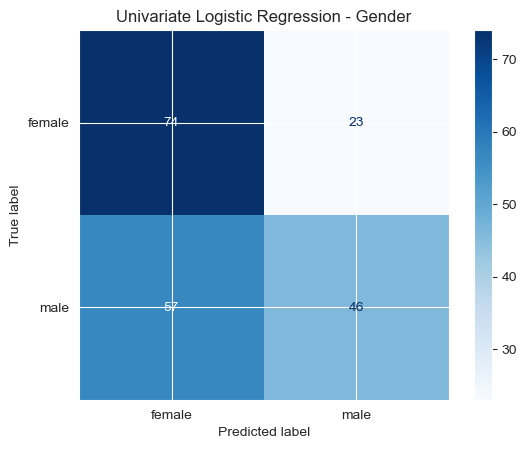

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

cm_uni = confusion_matrix(y_test_u, y_pred_u)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_uni,
    display_labels=le.classes_
)

disp.plot(cmap='Blues')

plt.title('Univariate Logistic Regression - Gender')
plt.show()

In [21]:
print("Coefficient:", log_uni.coef_)
print("Intercept:", log_uni.intercept_)

Coefficient: [[0.02088657]]
Intercept: [-1.49688893]


### **Multivariate Logistic Regression**

In [22]:
X_multi = df[
    [
        'math score',
        'reading score',
        'writing score'
    ]
]

y_multi = df['gender_encoded']

In [23]:
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi,
    y_multi,
    test_size=0.2,
    random_state=42
)

In [24]:
log_multi = LogisticRegression(max_iter=1000)

log_multi.fit(X_train_m, y_train_m)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [25]:
y_pred_m = log_multi.predict(X_test_m)

y_pred_m

array([1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0,
       0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0,
       0, 0])

In [26]:
print("Accuracy:", accuracy_score(y_test_m, y_pred_m))

print("Confusion Matrix:")
print(confusion_matrix(y_test_m, y_pred_m))

print("Classification Report:")
print(classification_report(y_test_m, y_pred_m))

Accuracy: 0.895
Confusion Matrix:
[[90  7]
 [14 89]]
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90        97
           1       0.93      0.86      0.89       103

    accuracy                           0.90       200
   macro avg       0.90      0.90      0.89       200
weighted avg       0.90      0.90      0.89       200



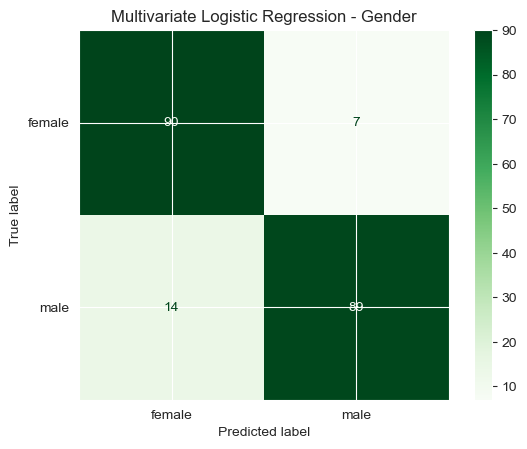

In [27]:
cm_multi = confusion_matrix(y_test_m, y_pred_m)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_multi,
    display_labels=le.classes_
)

disp.plot(cmap='Greens')

plt.title('Multivariate Logistic Regression - Gender')
plt.show()

In [28]:
print("Coefficients:", log_multi.coef_)
print("Intercept:", log_multi.intercept_)

Coefficients: [[ 0.35622686 -0.05772328 -0.32318622]]
Intercept: [2.29060826]


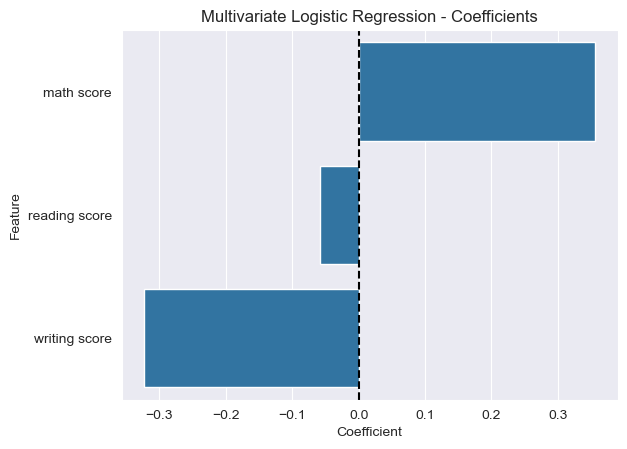

In [29]:
coef_df = pd.DataFrame({
    'Feature': X_multi.columns,
    'Coefficient': log_multi.coef_[0]
})

sns.barplot(
    data=coef_df,
    x='Coefficient',
    y='Feature'
)

plt.axvline(0, color='black', linestyle='--')
plt.title('Multivariate Logistic Regression - Coefficients')
plt.show()

### **Insight:-**
This model uses all three exam scores together. Positive coefficients increase the predicted log-odds of the encoded Male class, while negative coefficients decrease them, holding other scores constant.

### **Comparison Between Univariate and Multivariate models**

          Model  Accuracy
0    Univariate     0.600
1  Multivariate     0.895


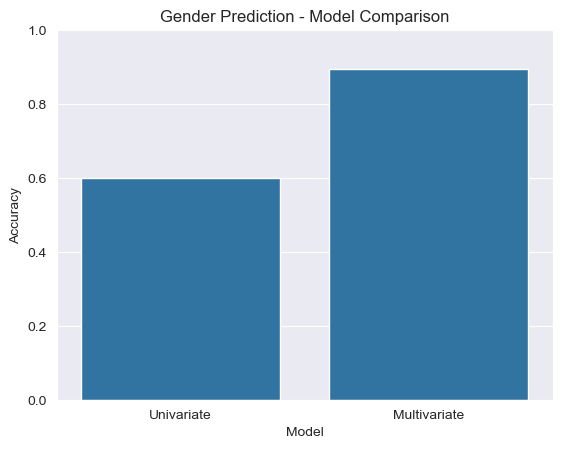

In [30]:
comparison = pd.DataFrame({
    'Model': ['Univariate', 'Multivariate'],
    'Accuracy': [
        accuracy_score(y_test_u, y_pred_u),
        accuracy_score(y_test_m, y_pred_m)
    ]
})

print(comparison)

sns.barplot(
    data=comparison,
    x='Model',
    y='Accuracy'
)

plt.title('Gender Prediction - Model Comparison')
plt.ylim(0, 1)
plt.show()

## 📊 Final Insights – Logistic Regression for Gender Prediction

- **Univariate Model:** Used Math Score as a single feature to predict gender.
- **Multivariate Model:** Combined Math, Reading, and Writing Scores to evaluate whether multiple features improved prediction performance.
- **Model Evaluation:** Compared accuracy, classification reports, and confusion matrices to understand the models' strengths and errors.
- **Key Learning:** Using multiple features does not always guarantee better predictions; model performance must be evaluated using test data.

### 🎯 Conclusion
This project demonstrates the practical application of Logistic Regression in a binary classification problem, including data preprocessing, model training, prediction, visualization, and performance evaluation.

**Note:** Exam scores are not a reliable indicator of an individual's gender. This project is intended for learning classification techniques, not for real-world gender prediction.